In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import alc
import ejercicio3
import cv2

In [2]:
filepath_base = '../template-alumnos/calib/coplanar'

objPts = np.loadtxt(f'{filepath_base}/p_corners.txt')
imgPtsList = np.loadtxt(f'{filepath_base}/detected_corners.txt')  


print(objPts)
print(objPts.shape)

[[  0.   0.]
 [300.   0.]
 [  0. 180.]
 [300. 180.]]
(4, 2)


In [3]:
print(imgPtsList)
print(imgPtsList.shape)

[[372. 104. 774. 112. 369. 351. 772. 356.]
 [384. 175. 778.  84. 441. 415. 832. 323.]
 [384. 135. 793. 115. 399. 389. 807. 363.]
 [405. 114. 817. 109. 410. 367. 816. 357.]
 [415.  75. 819. 110. 397. 328. 804. 356.]
 [408.  92. 813. 108. 403. 346. 809. 354.]
 [405. 146. 818. 132. 416. 398. 820. 380.]
 [390. 133. 796. 114. 409. 397. 817. 359.]
 [360. 150. 778.  72. 412. 402. 812. 322.]
 [387.  82. 795.  61. 397. 333. 827. 305.]]
(10, 8)


In [4]:
l = imgPtsList[0].reshape(-1,2)
print(l)
print(l.shape)
print(np.shape(l))


[[372. 104.]
 [774. 112.]
 [369. 351.]
 [772. 356.]]
(4, 2)
(4, 2)


In [5]:
Hs = []

for imgPts in imgPtsList:
    imgPts = imgPts.reshape(-1,2)
    Hs.append(ejercicio3.resolverDLT2D(imgPts, objPts))

print(Hs)

[array([[ 7.86097470e-01, -1.23932396e-02,  2.13163550e+02],
       [ 1.79214076e-02,  7.83606962e-01,  5.95941109e+01],
       [ 2.35791639e-05, -7.70433965e-06,  5.73020297e-01]]), array([[ 7.61256427e-01,  1.90568161e-01,  2.19641199e+02],
       [-1.72415878e-01,  7.71526908e-01,  1.00096900e+02],
       [ 1.29216222e-05,  2.14068853e-05,  5.71982288e-01]]), array([[-8.10675242e-01, -4.93498744e-02, -2.18037547e+02],
       [ 3.25509443e-02, -8.03219269e-01, -7.66538253e+01],
       [-4.61112749e-05, -5.09448201e-06, -5.67806113e-01]]), array([[-8.08487534e-01, -3.48054898e-02, -2.28998425e+02],
       [ 5.15904522e-03, -8.11836832e-01, -6.44588160e+01],
       [-3.91262229e-05, -4.65832941e-05, -5.65428211e-01]]), array([[ 8.11042293e-01, -6.47590984e-02,  2.35982019e+02],
       [ 7.24226120e-02,  7.92719368e-01,  4.26473529e+01],
       [ 5.52935030e-05, -1.98890711e-05,  5.68631372e-01]]), array([[-8.14494683e-01,  1.84457506e-02, -2.31043228e+02],
       [-3.68455775e-02, -7.9

---

### Test visual

[[408.  92.]
 [813. 108.]
 [403. 346.]
 [809. 354.]]


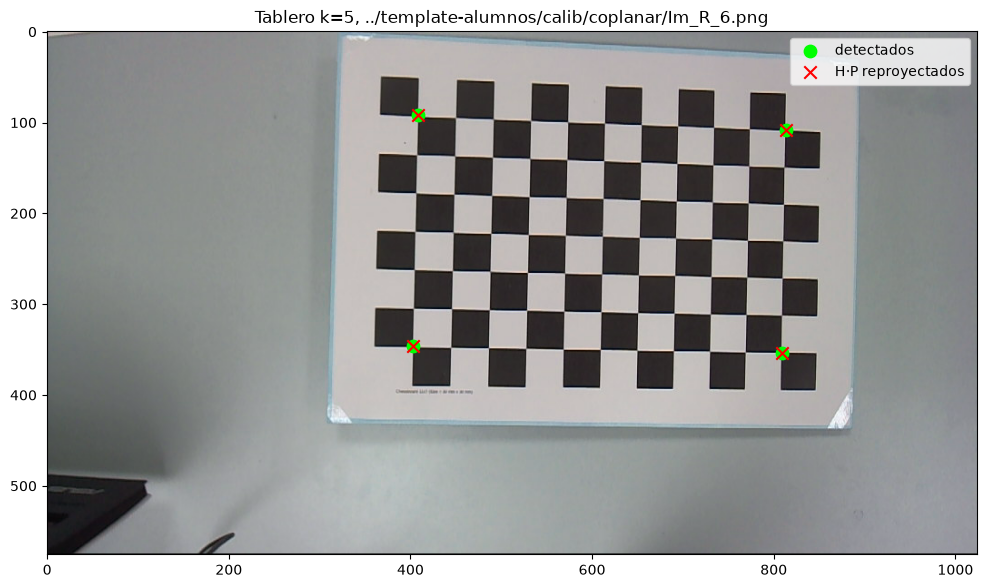

In [6]:
k = 5  # tablero a ver: 0..9

imgPts = imgPtsList[k].reshape(-1, 2)
H = ejercicio3.resolverDLT2D(imgPts, objPts)

P = np.vstack((objPts.T, np.ones((1, objPts.shape[0]))))

# Reproyectar: m ~ H·P, después dividir por la 3ra coordenada
m = alc.multiplicar(H, P)
#m = H @ P
res_proy = (m[:2] / m[2]).T
print(res_proy)

filename = f'{filepath_base}/Im_R_{k+1}.png'
img = cv2.imread(filename)
plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.scatter(imgPts[:, 0], imgPts[:, 1], c='lime', marker='o', s=80, label='detectados')
plt.scatter(res_proy[:, 0], res_proy[:, 1], c='red', marker='x', s=80, label='H·P reproyectados')
plt.title(f'Tablero k={k}, {filename}')
plt.legend()
plt.show()

### Test visual con todas las esquinas
Con 4 puntos H pasa justo por las esquinas marcadas, así que el test de arriba siempre da bien. Proyectamos las 77 esquinas internas: solo las 4 extremas se usaron para estimar H.

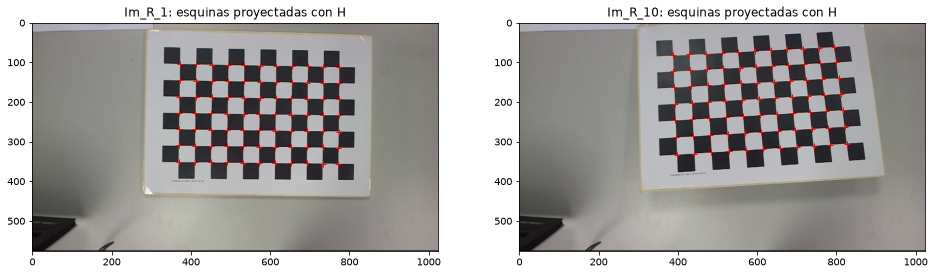

In [ ]:
# Las 11 x 7 esquinas internas del tablero (mm)
esquinas = []
for j in range(7):
    for i in range(11):
        esquinas.append([30.0 * i, 30.0 * j])
esquinas = np.array(esquinas)

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
for eje, k in zip(ejes, [0, 9]):
    proyectadas = alc.aplicarHomografia(Hs[k], esquinas)
    eje.imshow(cv2.imread(f'{filepath_base}/Im_R_{k + 1}.png')[:, :, ::-1])
    eje.plot(proyectadas[:, 0], proyectadas[:, 1], 'r+', markersize=6)
    eje.set_title(f'Im_R_{k + 1}: esquinas proyectadas con H')
plt.show()

---

In [7]:
A = ejercicio3.armarA(Hs)
A

array([[-9.74229431e-03,  6.15769346e-01,  1.40433398e-02,
        -6.34858414e-06,  1.83387244e-05, -1.81661887e-10],
       [ 6.17795641e-01,  4.75988040e-02, -6.13718693e-01,
         3.68800787e-05,  1.29194920e-05,  4.96620120e-10],
       [ 1.45071237e-01,  5.54472841e-01, -1.33023489e-01,
         1.87585788e-05,  6.27849227e-06,  2.76611683e-10],
       [ 5.43195124e-01, -5.56562318e-01, -5.65526535e-01,
         1.15143943e-05, -3.74877617e-05, -2.91286418e-10],
       [ 4.00067214e-02,  6.49543590e-01, -2.61455457e-02,
         6.40555606e-06,  3.68716343e-05,  2.34913060e-10],
       [ 6.54758938e-01, -1.32054029e-01, -6.44101630e-01,
         7.42597138e-05, -1.11859033e-05,  2.10029593e-09],
       [ 2.81398046e-02,  6.56180395e-01, -4.18830293e-03,
         3.90238199e-05,  3.15237835e-05,  1.82262835e-09],
       [ 6.52440670e-01, -6.48548046e-02, -6.59052426e-01,
         6.00234182e-05, -7.60397757e-05, -6.39141970e-10],
       [-5.25223677e-02,  6.38238911e-01,  5.741

In [8]:
K = ejercicio3.calcularMatrizK2D(A)
K

array([[902.74402932,   0.93859449, 535.00195548],
       [  0.        , 918.73610298, 284.54069292],
       [  0.        ,   0.        ,   1.        ]])

In [10]:
for j in range(len(Hs)):
    H = Hs[j]
    R, t = ejercicio3.obtenerPose2D(H, K)
    print(f"R{j}: {R}")
    print(f"t{j}: {t}")
    print("-"*20)

R0: [[ 0.99952023 -0.01172614 -0.0275736 ]
 [ 0.01423676  0.99777562  0.00866082]
 [ 0.02750683 -0.00898768  0.99746386]]
t0: [-120.56426633 -131.36099801  668.47030128]
--------------------
R1: [[ 0.97458908  0.23034657 -0.02021601]
 [-0.22349298  0.97147476 -0.02085634]
 [ 0.01506713  0.02496129  0.99826953]]
t1: [-111.4787519   -79.52081627  666.95437919]
--------------------
R2: [[-0.99698183 -0.0580966  -0.0530874 ]
 [ 0.05691867 -0.99921578 -0.00274819]
 [-0.0527968  -0.00583311  0.99950675]]
t2: [ 108.63726816  105.82032859 -650.13043877]
--------------------
R3: [[-0.99878995 -0.0114993  -0.045658  ]
 [ 0.02030176 -0.99512465 -0.05275128]
 [-0.04479367 -0.0533309   0.99415396]]
t3: [  93.09558046  120.1609824  -647.33073855]
--------------------
R4: [[ 0.99545012 -0.06998201 -0.06517245]
 [ 0.07096108  0.99937294  0.01831887]
 [ 0.06358923 -0.02287304  0.99979191]]
t4: [ -86.77378909 -149.14815327  653.94359058]
--------------------
R5: [[-0.9971918   0.01997602 -0.07113501]
 [